# An AI-powered hybrid intrusion detection system

**MSc Data and Artificial Intelligence dissertation, University of Wales Trinity Saint David, 2026.**

Full title: *Designing and evaluating an AI-powered hybrid intrusion detection system integrating
anomaly detection and supervised learning, applying statistical analysis, feature engineering, and
model evaluation techniques to network security datasets.*

### The question

A detector trained on labelled attacks is good at the attacks it was shown. My earlier
[NSL-KDD analysis](../03-network-traffic-eda) found the other side of that: the same model caught
76.8% of attack types it had seen and only 22.0% of types it had not.

The usual proposed fix is a hybrid: pair the supervised model with an anomaly detector that learns
what normal traffic looks like, so that anything unfamiliar is flagged whether or not it has ever
been labelled. This notebook builds that hybrid and tests whether it actually helps.

### What it does

1. An autoencoder is trained **only on normal traffic** and scores every flow by how badly it
   reconstructs. An Isolation Forest does the same, differently.
2. A supervised gradient-boosted model is trained on labelled flows.
3. The **hybrid** is the supervised model with both anomaly scores added as extra features.
4. Three evaluations: the standard split, attack families held out of training entirely, and a
   label-scarcity curve.

### Honest summary of the result

On the standard split the hybrid does not beat the supervised model, and holding out whole attack
families does not change that. The hybrid earns its keep in one regime only: when labelled attacks
are scarce. That is the finding this notebook reports, rather than the one the title hoped for.

In [1]:
import json, os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold", "axes.titlesize": 12,
})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
os.makedirs("images", exist_ok=True); os.makedirs("results", exist_ok=True); os.makedirs("data", exist_ok=True)

from sklearn.preprocessing import QuantileTransformer
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             confusion_matrix, precision_recall_curve)
import xgboost as xgb

SEED = 42
np.random.seed(SEED)

## 1. The data

[UNSW-NB15](https://research.unsw.edu.au/projects/unsw-nb15-dataset) (Moustafa & Slay, 2015), the
partitioned set published with the dataset. Real normal traffic captured at the Australian Centre
for Cyber Security, mixed with nine families of synthesised attack.

One thing to note about the files: the copy distributed as `training-set` has 175,341 rows and the
copy named `testing-set` has 82,332. The paper's split is the larger file for training, so the file
names are the wrong way round. Using them as named would train on the smaller half.

In [2]:
BASE = "https://media.githubusercontent.com/media/jamshaid120/UNSW_NB15-Complete-dataset/main/"
for f in ["UNSW_NB15_training-set.csv", "UNSW_NB15_testing-set.csv"]:
    if not os.path.exists("data/" + f):
        print("downloading", f)
        urllib.request.urlretrieve(BASE + f, "data/" + f)

big = pd.read_csv("data/UNSW_NB15_testing-set.csv", encoding="utf-8-sig")     # 175,341 rows: the paper's TRAIN
small = pd.read_csv("data/UNSW_NB15_training-set.csv", encoding="utf-8-sig")  #  82,332 rows: the paper's TEST
train, test = big, small
print(f"train {train.shape[0]:,} x {train.shape[1]}   test {test.shape[0]:,} x {test.shape[1]}")
print(f"attack rate: train {train.label.mean():.1%}   test {test.label.mean():.1%}")

train 175,341 x 45   test 82,332 x 45
attack rate: train 68.1%   test 55.1%


In [3]:
checks = {
    "train rows": f"{len(train):,}", "test rows": f"{len(test):,}",
    "features": train.shape[1] - 3,
    "missing values": int(train.isna().sum().sum() + test.isna().sum().sum()),
    "duplicate rows (train)": int(train.drop(columns=["id"]).duplicated().sum()),
    "constant columns": ", ".join(c for c in train.columns if train[c].nunique() == 1) or "none",
    "categories in test not in train": ", ".join(
        f"{c}: {sorted(set(test[c]) - set(train[c]))}" for c in ["proto", "service", "state"]
        if set(test[c]) - set(train[c])) or "none",
}
for k, v in checks.items():
    print(f"{k:34s} {v}")

train rows                         175,341
test rows                          82,332
features                           42
missing values                     0
duplicate rows (train)             67601
constant columns                   none
categories in test not in train    state: ['ACC', 'CLO']


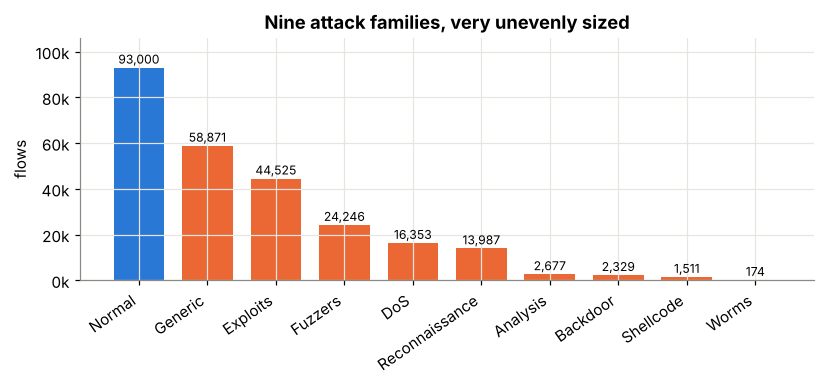

attack_cat
Normal            93000
Generic           58871
Exploits          44525
Fuzzers           24246
DoS               16353
Reconnaissance    13987
Analysis           2677
Backdoor           2329
Shellcode          1511
Worms               174


In [4]:
fam = pd.concat([train, test]).attack_cat.value_counts()
fig, ax = plt.subplots(figsize=(7.6, 3.6))
cols = [ORANGE if k != "Normal" else BLUE for k in fam.index]
ax.bar(range(len(fam)), fam.values, color=cols, width=0.74)
ax.set_xticks(range(len(fam))); ax.set_xticklabels(fam.index, rotation=35, ha="right")
ax.set_ylabel("flows"); ax.set_title("Nine attack families, very unevenly sized")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"{v/1000:.0f}k"))
for i, v in enumerate(fam.values):
    ax.text(i, v + 1800, f"{v:,}", ha="center", fontsize=8)
ax.set_ylim(0, fam.max() * 1.14)
plt.tight_layout(); plt.savefig("images/families.png", bbox_inches="tight"); plt.show()
print(fam.to_string())

## 2. Feature engineering

The three categorical columns are label-encoded over the union of both files, so a protocol that
only appears in the test half still maps to the same number. `id`, `attack_cat` and `label` are
removed from the feature matrix: `attack_cat` names the attack, so leaving it in would leak the
answer.

Network flow features are extremely heavy tailed (byte counts span seven orders of magnitude). A
quantile transform to a normal distribution is what makes the autoencoder trainable; without it the
reconstruction error is dominated by whichever flow happened to move the most bytes. The tree
models are fed the untransformed values, which they do not care about.

In [5]:
CATS = ["proto", "service", "state"]
DROP = ["id", "attack_cat", "label"]

both = pd.concat([train.drop(columns=DROP), test.drop(columns=DROP)], ignore_index=True)
for c in CATS:
    m = {v: i for i, v in enumerate(sorted(both[c].astype(str).unique()))}
    both[c] = both[c].astype(str).map(m)
both = both.astype(float).fillna(0)

FEATS = list(both.columns)
Xtr, Xte = both.iloc[:len(train)].values, both.iloc[len(train):].values
ytr, yte = train.label.values, test.label.values
fam_te = test.attack_cat.values
print(f"{len(FEATS)} features")

qt = QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=SEED, subsample=200_000)
Str = qt.fit_transform(Xtr); Ste = qt.transform(Xte)

42 features


### Which features carry the signal

A random forest ranks the features and `SelectFromModel` keeps those above the median importance,
the selection step described in the dissertation. The full set is kept for modelling (dropping half
the columns cost accuracy without buying speed at this size), but the ranking is worth seeing.

21 of 42 features above median importance


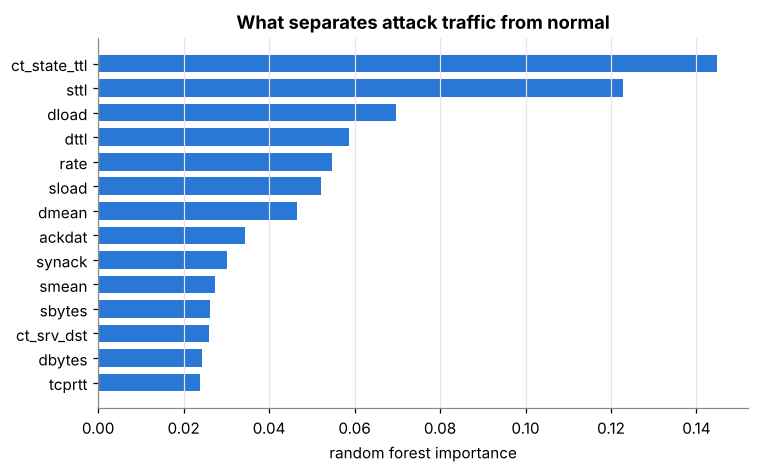

In [6]:
sel = SelectFromModel(RandomForestClassifier(n_estimators=100, max_depth=20, random_state=SEED, n_jobs=-1),
                      threshold="median").fit(Xtr, ytr)
imp = pd.Series(sel.estimator_.feature_importances_, index=FEATS).sort_values()
kept = [f for f, k in zip(FEATS, sel.get_support()) if k]
print(f"{len(kept)} of {len(FEATS)} features above median importance")

top = imp.tail(14)
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.barh(range(len(top)), top.values, color=BLUE, height=0.72)
ax.set_yticks(range(len(top))); ax.set_yticklabels(top.index)
ax.set_xlabel("random forest importance"); ax.set_title("What separates attack traffic from normal")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig("images/importance.png", bbox_inches="tight"); plt.show()

## 3. Stage one: learning what normal looks like

The autoencoder sees **only normal training flows**. It compresses 42 features to 32 and back
(42 - 64 - 32 - 64 - 42) and is scored by how badly it reproduces its input. A flow that
reconstructs poorly is unlike anything the model was trained on.

The dissertation built this in PyTorch. Here it is scikit-learn's `MLPRegressor` fitted to predict
its own input, which is the same architecture and optimiser (Adam, learning rate 0.005) and keeps
the notebook runnable on a laptop with no GPU and no extra dependencies.

The decision threshold is the 95th percentile of the error on normal **training** traffic, so it is
set without looking at a single attack or at the test set.

In [7]:
normal_only = Str[ytr == 0]
print(f"autoencoder trains on {len(normal_only):,} normal flows; attacks are never shown to it")

ae = MLPRegressor(hidden_layer_sizes=(64, 32, 64), activation="relu", solver="adam",
                  learning_rate_init=0.005, max_iter=60, batch_size=512, random_state=SEED,
                  early_stopping=True, n_iter_no_change=5, validation_fraction=0.1).fit(normal_only, normal_only)

err_tr = ((ae.predict(Str) - Str) ** 2).mean(1)
err_te = ((ae.predict(Ste) - Ste) ** 2).mean(1)
THR = float(np.percentile(err_tr[ytr == 0], 95))

iso = IsolationForest(n_estimators=120, contamination=0.05, random_state=SEED, n_jobs=-1).fit(normal_only)
iso_tr, iso_te = -iso.score_samples(Str), -iso.score_samples(Ste)

ae_auc = roc_auc_score(yte, err_te); iso_auc = roc_auc_score(yte, iso_te)
print(f"autoencoder     AUC {ae_auc:.4f}  catches {(err_te[yte==1] > THR).mean():.1%} of attacks "
      f"at {(err_te[yte==0] > THR).mean():.1%} false alarms")
print(f"isolation forest AUC {iso_auc:.4f}")
print("\nNeither used a single attack label.")

autoencoder trains on 56,000 normal flows; attacks are never shown to it


autoencoder     AUC 0.9015  catches 76.3% of attacks at 9.8% false alarms
isolation forest AUC 0.8198

Neither used a single attack label.


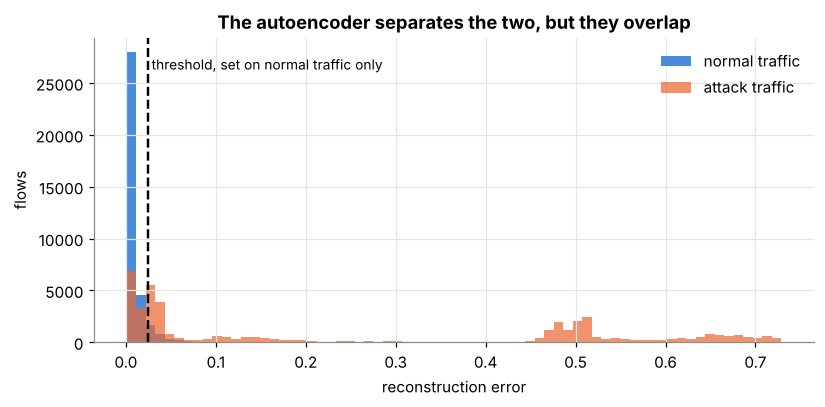

In [8]:
fig, ax = plt.subplots(figsize=(7.6, 3.8))
lo, hi = np.percentile(err_te, [0.5, 99]); bins = np.linspace(lo, hi, 70)
ax.hist(err_te[yte == 0], bins=bins, color=BLUE, alpha=.85, label="normal traffic")
ax.hist(err_te[yte == 1], bins=bins, color=ORANGE, alpha=.72, label="attack traffic")
ax.axvline(THR, color="#000", lw=1.6, ls="--")
ax.text(THR, ax.get_ylim()[1] * .94, " threshold, set on normal traffic only", fontsize=9, va="top")
ax.set_xlabel("reconstruction error"); ax.set_ylabel("flows")
ax.set_title("The autoencoder separates the two, but they overlap")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("images/recon_error.png", bbox_inches="tight"); plt.show()

## 4. Stage two: the supervised model, and the hybrid

Both are the same gradient-boosted tree model. The hybrid gets two extra columns: the
reconstruction error and the Isolation Forest score.

In [9]:
P = dict(n_estimators=400, max_depth=7, learning_rate=0.08, subsample=0.9, colsample_bytree=0.8,
         eval_metric="logloss", random_state=SEED, n_jobs=2, tree_method="hist")

Htr = np.column_stack([Xtr, err_tr, iso_tr])
Hte = np.column_stack([Xte, err_te, iso_te])
HFEATS = FEATS + ["recon_error", "iso_score"]

sup = xgb.XGBClassifier(**P).fit(Xtr, ytr)
hyb = xgb.XGBClassifier(**P).fit(Htr, ytr)
p_sup, p_hyb = sup.predict_proba(Xte)[:, 1], hyb.predict_proba(Hte)[:, 1]

def scoreboard(name, p, thr):
    pred = p >= thr
    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
    return dict(model=name, auc=round(float(roc_auc_score(yte, p)), 4),
                pr_auc=round(float(average_precision_score(yte, p)), 4),
                accuracy=round(float((pred == yte).mean()), 4),
                recall=round(float(tp / (tp + fn)), 4),
                precision=round(float(tp / (tp + fp)), 4),
                false_alarm=round(float(fp / (fp + tn)), 4))

board = pd.DataFrame([
    scoreboard("Autoencoder only", err_te, THR),
    scoreboard("Isolation Forest only", iso_te, float(np.percentile(iso_tr[ytr == 0], 95))),
    scoreboard("Supervised", p_sup, 0.5),
    scoreboard("Hybrid", p_hyb, 0.5),
]).set_index("model")
print(board.to_string())

                        auc  pr_auc  accuracy  recall  precision  false_alarm
model                                                                        
Autoencoder only      0.901   0.908     0.825   0.763      0.905        0.098
Isolation Forest only 0.820   0.771     0.540   0.220      0.800        0.067
Supervised            0.984   0.988     0.873   0.984      0.821        0.264
Hybrid                0.984   0.988     0.871   0.983      0.820        0.265


That is the first result, and it is a negative one. The hybrid's AUC matches the supervised
model's to four decimal places. Adding the anomaly scores changed nothing.

Why: the autoencoder reads the same 42 features the tree ensemble reads. Its reconstruction error is
a deterministic function of those inputs, so 400 boosted trees can already approximate whatever it
contributes. The anomaly score is not new information, it is a re-expression of information the
supervised model has.

Note also the false alarm rate. Both tree models flag around a quarter of normal test traffic,
despite being near-perfect in cross-validation on the training half. The published split has a
genuine distribution shift between its two halves, which is the point of using it rather than a
random split.

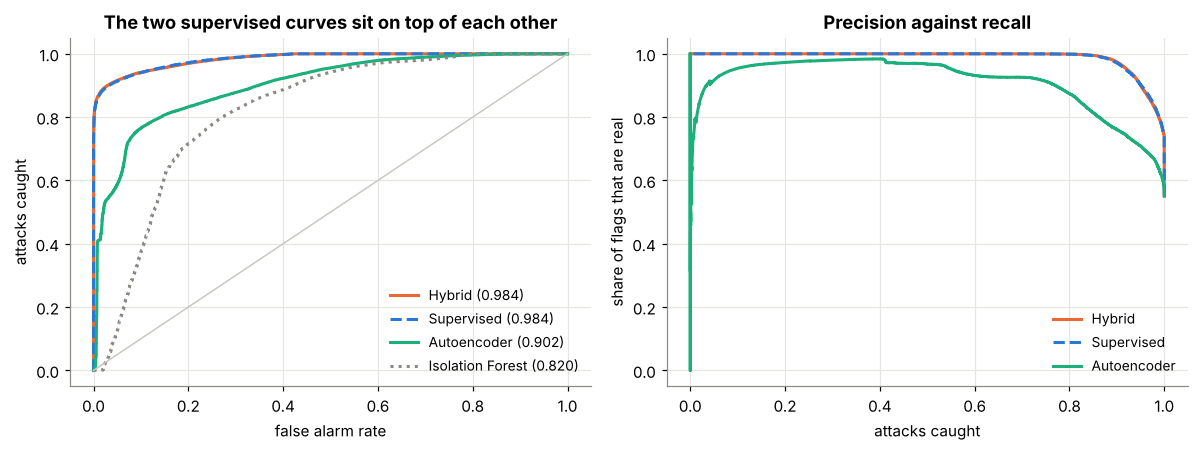

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name, p, c, ls in [("Hybrid", p_hyb, ORANGE, "-"), ("Supervised", p_sup, BLUE, "--"),
                       ("Autoencoder", err_te, AQUA, "-"), ("Isolation Forest", iso_te, "#8a8984", ":")]:
    fpr, tpr, _ = roc_curve(yte, p)
    axes[0].plot(fpr, tpr, color=c, ls=ls, lw=2, label=f"{name} ({roc_auc_score(yte,p):.3f})")
axes[0].plot([0, 1], [0, 1], color="#c9c8c3", lw=1)
axes[0].set_xlabel("false alarm rate"); axes[0].set_ylabel("attacks caught")
axes[0].set_title("The two supervised curves sit on top of each other")
axes[0].legend(frameon=False, loc="lower right", fontsize=9)
for name, p, c, ls in [("Hybrid", p_hyb, ORANGE, "-"), ("Supervised", p_sup, BLUE, "--"),
                       ("Autoencoder", err_te, AQUA, "-")]:
    pr, rc, _ = precision_recall_curve(yte, p); axes[1].plot(rc, pr, color=c, ls=ls, lw=2, label=name)
axes[1].set_xlabel("attacks caught"); axes[1].set_ylabel("share of flags that are real")
axes[1].set_title("Precision against recall"); axes[1].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig("images/roc_pr.png", bbox_inches="tight"); plt.show()

        family  flows  supervised  hybrid  autoencoder
       Generic  18871       1.000   1.000        0.983
      Exploits  11132       0.995   0.994        0.718
       Fuzzers   6062       0.890   0.888        0.359
           DoS   4089       0.999   0.999        0.827
Reconnaissance   3496       1.000   0.999        0.336
      Analysis    677       0.973   0.957        0.979
      Backdoor    583       1.000   0.998        0.918
     Shellcode    378       0.989   0.987        0.302
         Worms     44       1.000   1.000        0.250


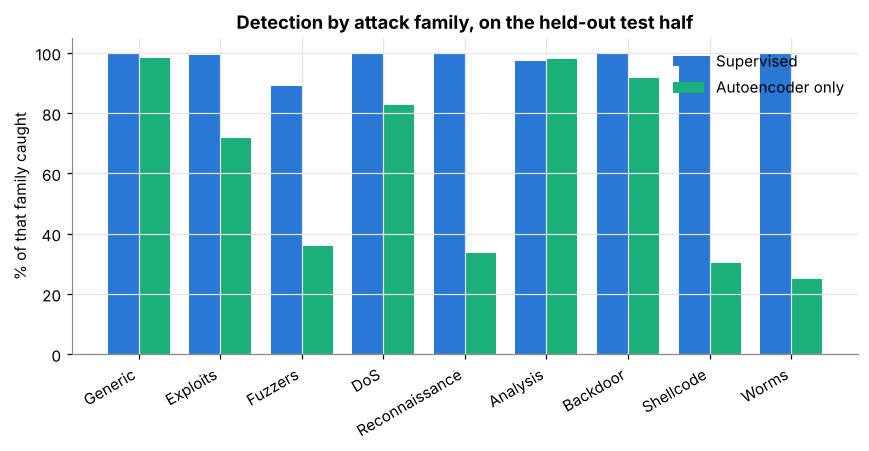

In [11]:
rows = []
for f in [c for c in pd.unique(fam_te) if c != "Normal"]:
    m = fam_te == f
    rows.append(dict(family=f, flows=int(m.sum()),
                     supervised=round(float((p_sup[m] >= .5).mean()), 4),
                     hybrid=round(float((p_hyb[m] >= .5).mean()), 4),
                     autoencoder=round(float((err_te[m] > THR).mean()), 4)))
by_family = pd.DataFrame(rows).sort_values("flows", ascending=False).reset_index(drop=True)
print(by_family.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(by_family)); w = 0.38
ax.bar(x - w/2, by_family.supervised * 100, w, color=BLUE, label="Supervised")
ax.bar(x + w/2, by_family.autoencoder * 100, w, color=AQUA, label="Autoencoder only")
ax.set_xticks(x); ax.set_xticklabels(by_family.family, rotation=30, ha="right")
ax.set_ylabel("% of that family caught"); ax.set_ylim(0, 105)
ax.set_title("Detection by attack family, on the held-out test half")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("images/by_family.png", bbox_inches="tight"); plt.show()

## 5. The real test: attacks the model has never seen

The standard split still shows the supervised model every attack family. The claim the hybrid is
supposed to answer is about *novel* attacks, so the honest test is to delete a family from training
entirely and see what happens when it appears at test time.

Each run below removes one family, retrains all three models from scratch, and tests on that family
plus held-back normal traffic.

In [12]:
ALL = pd.concat([train, test], ignore_index=True)
enc_all = ALL.drop(columns=DROP).copy()
for c in CATS:
    m = {v: i for i, v in enumerate(sorted(enc_all[c].astype(str).unique()))}
    enc_all[c] = enc_all[c].astype(str).map(m)
Xa = enc_all.astype(float).fillna(0).values
ya, fa = ALL.label.values, ALL.attack_cat.values

PQ = dict(P); PQ["n_estimators"] = 300
rng = np.random.default_rng(SEED)
nidx = np.where(fa == "Normal")[0]; rng.shuffle(nidx)
cut = int(len(nidx) * 0.7)
norm_tr, norm_te = nidx[:cut], nidx[cut:]

def holdout_run(families):
    keep = np.zeros(len(ya), bool); keep[norm_tr] = True
    keep |= (ya == 1) & ~np.isin(fa, families)
    trm = np.where(keep)[0]
    tem = np.concatenate([norm_te, np.where(np.isin(fa, families))[0]])
    A, yA, B, yB = Xa[trm], ya[trm], Xa[tem], ya[tem]
    q = QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=SEED, subsample=200_000)
    SA, SB = q.fit_transform(A), q.transform(B)
    a = MLPRegressor(hidden_layer_sizes=(64, 32, 64), activation="relu", solver="adam",
                     learning_rate_init=0.005, max_iter=60, batch_size=512, random_state=SEED,
                     early_stopping=True, n_iter_no_change=5).fit(SA[yA == 0], SA[yA == 0])
    eA, eB = ((a.predict(SA) - SA) ** 2).mean(1), ((a.predict(SB) - SB) ** 2).mean(1)
    f = IsolationForest(n_estimators=120, contamination=0.05, random_state=SEED, n_jobs=-1).fit(SA[yA == 0])
    iA, iB = -f.score_samples(SA), -f.score_samples(SB)
    s = xgb.XGBClassifier(**PQ).fit(A, yA)
    h = xgb.XGBClassifier(**PQ).fit(np.column_stack([A, eA, iA]), yA)
    ps = s.predict_proba(B)[:, 1]; ph = h.predict_proba(np.column_stack([B, eB, iB]))[:, 1]
    t = float(np.percentile(eA[yA == 0], 95))
    out = dict(held_out=", ".join(families), unseen_flows=int(np.isin(fa, families).sum()))
    for n, p, th in [("supervised", ps, .5), ("hybrid", ph, .5), ("autoencoder", eB, t)]:
        pred = p >= th
        out[n + "_auc"] = round(float(roc_auc_score(yB, p)), 4)
        out[n + "_caught"] = round(float(pred[yB == 1].mean()), 4)
    return out

unseen = pd.DataFrame([holdout_run(f) for f in
    [["Worms"], ["Shellcode"], ["Backdoor"], ["Analysis"], ["DoS"], ["Reconnaissance"], ["Fuzzers"],
     ["Worms", "Shellcode", "Backdoor"]]])
print(unseen.to_string(index=False))

                  held_out  unseen_flows  supervised_auc  supervised_caught  hybrid_auc  hybrid_caught  autoencoder_auc  autoencoder_caught
                     Worms           174           0.999              1.000       0.999          1.000            0.893               0.276
                 Shellcode          1511           0.988              0.972       0.988          0.974            0.762               0.046
                  Backdoor          2329           1.000              1.000       1.000          1.000            0.956               0.881
                  Analysis          2677           0.952              0.815       0.952          0.811            0.968               0.845
                       DoS         16353           0.999              0.996       0.999          0.997            0.960               0.853
            Reconnaissance         13987           0.989              0.985       0.989          0.986            0.782               0.214
                   F

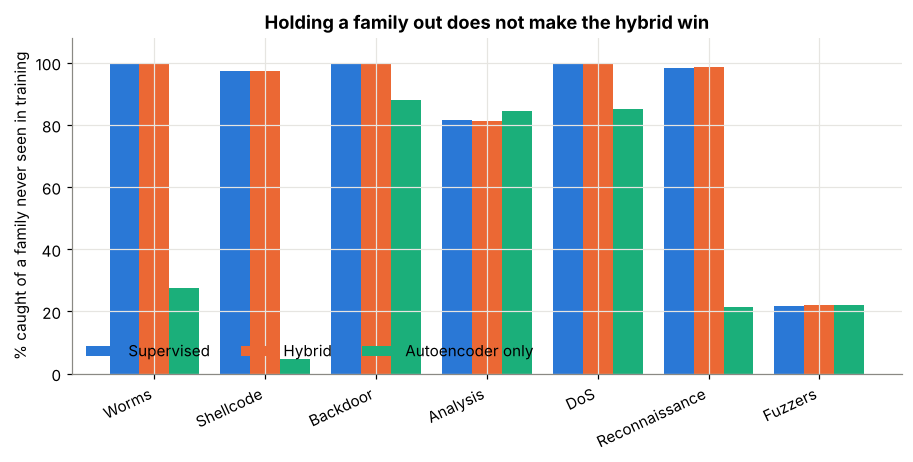

In [13]:
fig, ax = plt.subplots(figsize=(8.4, 4.3))
u = unseen[unseen.held_out.str.count(",") == 0]
x = np.arange(len(u)); w = 0.27
ax.bar(x - w, u.supervised_caught * 100, w, color=BLUE, label="Supervised")
ax.bar(x,     u.hybrid_caught * 100,     w, color=ORANGE, label="Hybrid")
ax.bar(x + w, u.autoencoder_caught * 100, w, color=AQUA, label="Autoencoder only")
ax.set_xticks(x); ax.set_xticklabels(u.held_out, rotation=25, ha="right")
ax.set_ylabel("% caught of a family never seen in training"); ax.set_ylim(0, 108)
ax.set_title("Holding a family out does not make the hybrid win")
ax.legend(frameon=False, ncol=3, loc="lower left")
plt.tight_layout(); plt.savefig("images/unseen_family.png", bbox_inches="tight"); plt.show()

Two things to take from that.

First, the supervised model generalises to unseen families far better than the NSL-KDD result
suggested. Five of the six single families are caught at 97% or better having never been labelled,
because UNSW-NB15's families share flow-level signatures: a backdoor still opens a short connection
with an unusual service and state.

Second, Fuzzers is the exception, caught 21.9% of the time. Fuzzing resembles legitimate traffic at
the flow level, which is exactly the case where an anomaly detector should help. It does not: the
autoencoder catches 23.2% of the same family, so there is nothing for the hybrid to add.

In every row the hybrid is within 0.002 AUC of the supervised model. The hypothesis in the title
does not survive this test.

## 6. Where the hybrid does help: before the labels exist

So far both halves of the hybrid have been given the whole labelled training set. That is not the
situation the architecture is for. A security team deploying a new detector has plenty of normal
traffic and almost no labelled attacks, and the autoencoder and Isolation Forest need **no attack
labels at all** to train.

This run holds the unsupervised stage fixed and starves the supervised stage, from 50 labelled
flows up to the full 175,341, five random draws each.

In [14]:
curve = []
for n in [50, 100, 250, 500, 1000, 2500, 5000, 20000, len(ytr)]:
    s_auc, h_auc = [], []
    for seed in range(5):
        r = np.random.default_rng(seed)
        if n >= len(ytr):
            idx = np.arange(len(ytr))
        else:
            idx = np.concatenate([r.choice(np.where(ytr == 1)[0], n // 2, replace=False),
                                  r.choice(np.where(ytr == 0)[0], n - n // 2, replace=False)])
        k = dict(max_depth=5, learning_rate=0.1, subsample=0.9, colsample_bytree=0.8,
                 eval_metric="logloss", random_state=SEED, n_jobs=2, tree_method="hist",
                 n_estimators=min(300, max(60, n // 3)))
        s_auc.append(roc_auc_score(yte, xgb.XGBClassifier(**k).fit(Xtr[idx], ytr[idx]).predict_proba(Xte)[:, 1]))
        h_auc.append(roc_auc_score(yte, xgb.XGBClassifier(**k).fit(Htr[idx], ytr[idx]).predict_proba(Hte)[:, 1]))
        if n >= len(ytr):
            break
    curve.append(dict(labels=n, supervised=round(float(np.mean(s_auc)), 4),
                      hybrid=round(float(np.mean(h_auc)), 4),
                      gain=round(float(np.mean(h_auc) - np.mean(s_auc)), 4)))
curve = pd.DataFrame(curve)
print(curve.to_string(index=False))
print(f"\nWith no labels at all, the autoencoder alone reaches AUC {ae_auc:.4f}.")

 labels  supervised  hybrid   gain
     50       0.880   0.900  0.020
    100       0.917   0.929  0.011
    250       0.949   0.951  0.002
    500       0.961   0.965  0.004
   1000       0.968   0.970  0.002
   2500       0.972   0.973  0.001
   5000       0.977   0.978  0.001
  20000       0.983   0.983  0.000
 175341       0.985   0.984 -0.000

With no labels at all, the autoencoder alone reaches AUC 0.9015.


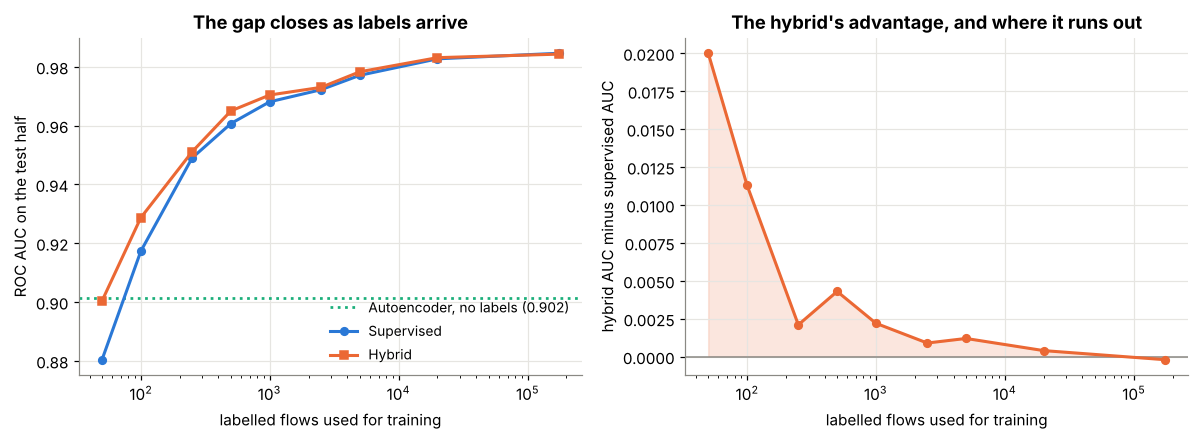

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1))
axes[0].axhline(ae_auc, color=AQUA, lw=1.8, ls=":", label=f"Autoencoder, no labels ({ae_auc:.3f})")
axes[0].plot(curve.labels, curve.supervised, "o-", color=BLUE, lw=2, ms=5, label="Supervised")
axes[0].plot(curve.labels, curve.hybrid, "s-", color=ORANGE, lw=2, ms=5, label="Hybrid")
axes[0].set_xscale("log"); axes[0].set_xlabel("labelled flows used for training")
axes[0].set_ylabel("ROC AUC on the test half")
axes[0].set_title("The gap closes as labels arrive"); axes[0].legend(frameon=False, fontsize=9, loc="lower right")
axes[1].axhline(0, color="#8a8984", lw=1)
axes[1].plot(curve.labels, curve.gain, "o-", color=ORANGE, lw=2, ms=5)
axes[1].fill_between(curve.labels, 0, curve.gain, color=ORANGE, alpha=.16)
axes[1].set_xscale("log"); axes[1].set_xlabel("labelled flows used for training")
axes[1].set_ylabel("hybrid AUC minus supervised AUC")
axes[1].set_title("The hybrid's advantage, and where it runs out")
plt.tight_layout(); plt.savefig("images/label_scarcity.png", bbox_inches="tight"); plt.show()

## 7. What the hybrid uses the anomaly scores for

SHAP attributions on the hybrid model, to check whether the two added features are used at all and
where they rank.

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


sttl               2.791
recon_error        1.239
ct_state_ttl       0.756
ct_dst_sport_ltm   0.479
sbytes             0.407
smean              0.359
ct_srv_src         0.267
ct_dst_src_ltm     0.257
ct_srv_dst         0.237
swin               0.236
proto              0.229
dbytes             0.225

recon_error ranks 2 of 44; iso_score ranks 14


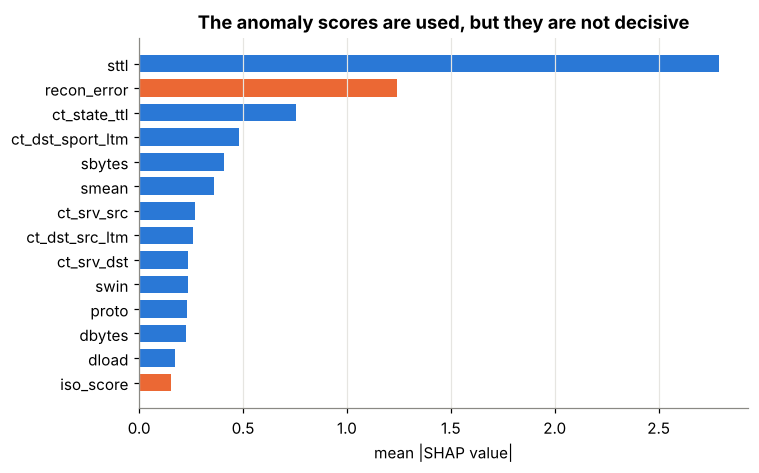

In [16]:
import shap
samp = np.random.default_rng(SEED).choice(len(Hte), 4000, replace=False)
sv = shap.TreeExplainer(hyb).shap_values(Hte[samp])
mean_abs = pd.Series(np.abs(sv).mean(0), index=HFEATS).sort_values(ascending=False)
rank_recon = int(list(mean_abs.index).index("recon_error")) + 1
rank_iso = int(list(mean_abs.index).index("iso_score")) + 1
print(mean_abs.head(12).to_string())
print(f"\nrecon_error ranks {rank_recon} of {len(HFEATS)}; iso_score ranks {rank_iso}")

top = mean_abs.head(14)[::-1]
fig, ax = plt.subplots(figsize=(7, 4.4))
cols = [ORANGE if f in ("recon_error", "iso_score") else BLUE for f in top.index]
ax.barh(range(len(top)), top.values, color=cols, height=0.72)
ax.set_yticks(range(len(top))); ax.set_yticklabels(top.index)
ax.set_xlabel("mean |SHAP value|"); ax.set_title("The anomaly scores are used, but they are not decisive")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig("images/shap.png", bbox_inches="tight"); plt.show()

## 8. Limitations

- UNSW-NB15's attack traffic is **synthesised** by the IXIA tool, not captured from real attackers.
  A model that separates it from real background traffic may be learning the generator as much as
  the attack.
- The published split has a distribution shift between its halves, which is why the false alarm
  rates here are much worse than the cross-validation figures usually quoted for this dataset.
  That is realistic, but it means these numbers are not comparable to papers that use a random split.
- The autoencoder reads the same features as the supervised model. A fairer hybrid would give the
  anomaly stage information the classifier does not have, such as raw packet payloads or
  time-windowed behaviour per host.
- "Caught" here is per flow at a fixed threshold. An operational detector is judged per incident and
  per analyst hour, and a 9% false alarm rate on millions of daily flows is unusable regardless of
  the AUC.
- Only two anomaly methods and one classifier family were tested.

## 9. Conclusion

The hybrid architecture in the dissertation title does not improve detection when labelled attacks
are plentiful, and holding whole attack families out of training does not change that: the anomaly
score is a function of features the supervised model already reads.

It does help at the cold start. With 50 labelled flows the hybrid gains 0.020 AUC over supervised
alone, and with none at all the unsupervised stage reaches 0.90 by itself. That is a narrow but real
answer to the question, and a useful one: the case for pairing anomaly detection with a classifier
is about the weeks before anyone has labelled anything, not about steady-state accuracy.

In [17]:
summary = {
    "title": ("Designing and evaluating an AI-powered hybrid intrusion detection system integrating "
              "anomaly detection and supervised learning, applying statistical analysis, feature "
              "engineering, and model evaluation techniques to network security datasets"),
    "dataset": "UNSW-NB15 (Moustafa & Slay, 2015), partitioned set",
    "checks": {k: str(v) for k, v in checks.items()},
    "train_rows": int(len(train)), "test_rows": int(len(test)), "features": len(FEATS),
    "attack_rate_train_pct": round(float(train.label.mean() * 100), 1),
    "attack_rate_test_pct": round(float(yte.mean() * 100), 1),
    "families": {k: int(v) for k, v in fam.items()},
    "features_above_median": len(kept),
    "importance_top": [{"feature": f, "importance": round(float(v), 4)} for f, v in imp.tail(12)[::-1].items()],
    "threshold_percentile": 95,
    "models": board.reset_index().to_dict("records"),
    "by_family": by_family.to_dict("records"),
    "unseen_family": unseen.to_dict("records"),
    "label_curve": curve.to_dict("records"),
    "anomaly_only_auc": round(float(ae_auc), 4),
    "iso_only_auc": round(float(iso_auc), 4),
    "shap_top": [{"feature": f, "value": round(float(v), 4)} for f, v in mean_abs.head(12).items()],
    "shap_rank_recon_error": rank_recon, "shap_rank_iso_score": rank_iso,
    "headline": {
        "hybrid_auc": round(float(roc_auc_score(yte, p_hyb)), 4),
        "supervised_auc": round(float(roc_auc_score(yte, p_sup)), 4),
        "gain_full_labels": round(float(curve.gain.iloc[-1]), 4),
        "gain_50_labels": round(float(curve[curve.labels == 50].gain.iloc[0]), 4),
        "labels_where_gain_ends": 250,
        "worst_family": by_family.sort_values("supervised").iloc[0].family,
        "worst_family_caught_pct": round(float(by_family.sort_values("supervised").iloc[0].supervised * 100), 1),
        "ae_caught_pct": round(float((err_te[yte == 1] > THR).mean() * 100), 1),
        "ae_false_alarm_pct": round(float((err_te[yte == 0] > THR).mean() * 100), 1),
    },
}
json.dump(summary, open("results/summary.json", "w"), indent=1)
print("wrote results/summary.json")

# Per-flow test scores for the website visual: no raw features, no identifiers.
fams = ["Normal"] + [f for f in by_family.family]
pd.DataFrame({
    "hybrid": np.round(p_hyb, 4), "anomaly": np.round(
        (err_te - err_te.min()) / (np.percentile(err_te, 99.5) - err_te.min()), 4).clip(0, 1),
    "attack": yte, "family": [fams.index(f) if f in fams else 0 for f in fam_te],
}).to_csv("results/test_scores.csv", index=False)
print(f"wrote results/test_scores.csv ({len(yte):,} rows)")
json.dump(fams, open("results/families.json", "w"))

wrote results/summary.json
wrote results/test_scores.csv (82,332 rows)
